# Tarea 4 — Física Computacional II

**Nombre:** Martina Guerrero Ramos  
**RUT:** 21.888.130-0  
**Fecha:** 20 de octubre de 2026

## Configuración inicial
Se fija una semilla pseudoaleatoria entre 0 y 100000 para obtener siempre el mismo catálogo.

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fijo la semilla para que los valores aleatorios sean reproducibles.
rng = np.random.default_rng(seed=18)

## Parte I: Generación del catálogo
Se genera una muestra de 100 estrellas, asignando valores aleatorios a sus radios, distancias y temperaturas efectivas mediante distribuciones uniformes independientes, considerando los intervalos establecidos en el enunciado.

In [71]:
# Genero una muestra de 100 estrellas con valores aleatorios para sus propiedades físicas.
n = 100
radio = rng.uniform(0.5, 5, n)       # Radio en radios solares.
distancia = rng.uniform(50, 500, n)  # Distancia en parsecs.
temperatura = rng.uniform(3000, 10000, n)  # Temperatura en kelvin.


# Organizo las propiedades de las estrellas en un diccionario.
datos = {"Estrella": np.arange(1, n + 1),
         "Radio (Rsol)": radio,
         "Distancia (pc)": distancia,
         "Temperatura (K)": temperatura}

# Construyo el catálogo de estrellas utilizando un DataFrame de Pandas.
catalogo = pd.DataFrame(datos)


# Muestro las primeras diez filas del catálogo.
display(catalogo.head(10))

# Obtengo las estadísticas descriptivas de las propiedades físicas.
display(catalogo[["Radio (Rsol)", "Distancia (pc)", "Temperatura (K)"]].describe())

,Estrella,Radio (Rsol),Distancia (pc),Temperatura (K)
0,1,2.296876,275.221699,7121.178452
1,2,3.728366,194.615490,9374.756745
2,3,1.763705,494.073725,7979.587998
3,4,0.872262,108.279142,8930.665756
4,5,4.863971,95.862324,4460.597577
5,6,3.037670,390.339881,5222.417302
6,7,3.399444,343.657105,4704.451281
7,8,3.095922,218.775534,7434.979743
8,9,2.639124,201.695233,6982.222760
9,10,1.050809,282.526187,3774.661058


,Radio (Rsol),Distancia (pc),Temperatura (K)
count,100.000000,100.000000,100.000000
mean,2.768822,270.759206,6655.690121
std,1.320114,138.048205,2002.627261
min,0.523640,55.437651,3044.906119
25%,1.581672,150.529881,4680.279402
50%,3.090079,275.659202,6757.029433
75%,3.769378,389.173144,8267.440391
max,4.993092,498.050642,9993.750180



## Parte II: Luminosidad y flujo observado

Se calcula la luminosidad de cada estrella mediante la ley de Stefan-Boltzmann:

$$
L = 4\pi R^2 \sigma_{SB} T_{eff}^4
$$

Posteriormente, se determina el flujo observado utilizando:

$$
F = \frac{L}{4\pi d^2}
$$

Para realizar los cálculos, se convierten los radios estelares de radios solares a metros y las distancias de parsecs a metros. Finalmente, las luminosidades obtenidas en watts se expresan en luminosidades solares.


In [72]:
# Defino las constantes físicas necesarias para los cálculos.
sigma = 5.670374419e-8       # Constante de Stefan-Boltzmann (W/m² K⁴).
Rsol = 6.957e8                # Radio solar en metros.
Lsol = 3.828e26               # Luminosidad solar en watts.
pc = 3.085677581491367e16    # Equivalencia de un parsec en metros.

# Convierto los radios y las distancias a metros para realizar los cálculos.
R = catalogo["Radio (Rsol)"] * Rsol
d = catalogo["Distancia (pc)"] * pc
T = catalogo["Temperatura (K)"]

# Calculo la luminosidad en watts y el flujo observado en W/m².
L = 4 * np.pi * R**2 * sigma * T**4
F = L / (4 * np.pi * d**2)

# Incorporo la luminosidad en unidades solares y el flujo observado al catálogo.
catalogo["Luminosidad (Lsol)"] = L / Lsol
catalogo["Flujo (W/m²)"] = F
display(catalogo.head(10))

,Estrella,Radio (Rsol),Distancia (pc),Temperatura (K),Luminosidad (Lsol),Flujo (W/m²)
0,1,2.296876,275.221699,7121.178452,12.222956,5.162640e-12
1,2,3.728366,194.615490,9374.756745,96.732141,8.171033e-11
2,3,1.763705,494.073725,7979.587998,11.362331,1.489172e-12
3,4,0.872262,108.279142,8930.665756,4.360367,1.189856e-11
4,5,4.863971,95.862324,4460.597577,8.438161,2.937737e-11
5,6,3.037670,390.339881,5222.417302,6.183883,1.298483e-12
6,7,3.399444,343.657105,4704.451281,5.099710,1.381516e-12
7,8,3.095922,218.775534,7434.979743,26.387166,1.763828e-11
8,9,2.639124,201.695233,6982.222760,14.913796,1.172892e-11
9,10,1.050809,282.526187,3774.661058,0.201954,8.094623e-14



Los números situados a la izquierda de las tablas corresponden a los índices originales del DataFrame de Pandas, mientras que la columna "Estrella" indica el identificador de cada estrella.


In [73]:
# Ordeno el catálogo para identificar los valores extremos.
print("Estrella con mayor luminosidad:")
display(catalogo.sort_values("Luminosidad (Lsol)", ascending=False).head(1))

print("Estrella con menor luminosidad:")
display(catalogo.sort_values("Luminosidad (Lsol)").head(1))

print("Estrella con mayor flujo observado:")
display(catalogo.sort_values("Flujo (W/m²)", ascending=False).head(1))

print("Estrella con menor flujo observado:")
display(catalogo.sort_values("Flujo (W/m²)").head(1))

Estrella con mayor luminosidad:


,Estrella,Radio (Rsol),Distancia (pc),Temperatura (K),Luminosidad (Lsol),Flujo (W/m²)
71,72,3.696548,433.066044,9945.310795,120.43694,2.054530e-11


Estrella con menor luminosidad:


,Estrella,Radio (Rsol),Distancia (pc),Temperatura (K),Luminosidad (Lsol),Flujo (W/m²)
23,24,0.533305,351.930766,3703.242162,0.048192,1.244857e-14


Estrella con mayor flujo observado:


,Estrella,Radio (Rsol),Distancia (pc),Temperatura (K),Luminosidad (Lsol),Flujo (W/m²)
27,28,2.978143,75.176,9617.857072,68.375133,3.870800e-10


Estrella con menor flujo observado:


,Estrella,Radio (Rsol),Distancia (pc),Temperatura (K),Luminosidad (Lsol),Flujo (W/m²)
23,24,0.533305,351.930766,3703.242162,0.048192,1.244857e-14



## Parte III: Clasificación de estrellas

Se clasifican las estrellas según su flujo observado, considerando un límite de detección de:

$$
F_{lim} = 2 \times 10^{-10}\ \mathrm{W/m^2}
$$

Las estrellas con un flujo mayor o igual a este límite se clasifican como "Detectada", mientras que aquellas con un flujo inferior se clasifican como "No detectada".


In [74]:
# Defino el límite de detección del telescopio.
Flim = 2e-10

# Clasifico las estrellas según su flujo observado.
catalogo["Clasificacion"] = np.where(
    catalogo["Flujo (W/m²)"] >= Flim,
    "Detectada",
    "No detectada"
)

# Cuento las estrellas de cada categoría.
conteo = catalogo["Clasificacion"].value_counts()

print("Estrellas por categoría:")
display(conteo)

# Calculo el porcentaje de estrellas detectadas.
porcentaje = 100 * (catalogo["Clasificacion"] == "Detectada").mean()

print(f"Porcentaje de estrellas detectadas: {porcentaje:.2f}%")

# Calculo el flujo, la distancia y la temperatura promedio de cada categoría.
filas = []
for categoria in ["Detectada", "No detectada"]:
    grupo = catalogo[catalogo["Clasificacion"] == categoria]
    filas.append({"Clasificacion": categoria,
                  "Cantidad": len(grupo),
                  "Flujo promedio (W/m²)": grupo["Flujo (W/m²)"].mean(),
                  "Distancia promedio (pc)": grupo["Distancia (pc)"].mean(),
                  "Temperatura promedio (K)": grupo["Temperatura (K)"].mean()})
resumen = pd.DataFrame(filas)
display(resumen)

Estrellas por categoría:


Clasificacion
No detectada    95
Detectada        5
Name: count, dtype: int64

Porcentaje de estrellas detectadas: 5.00%


,Clasificacion,Cantidad,Flujo promedio (W/m²),Distancia promedio (pc),Temperatura promedio (K)
0,Detectada,5,3.072725e-10,77.543736,8661.513656
1,No detectada,95,1.572783e-11,280.928441,6550.120462



## Parte IV: Visualización de resultados

Se representan gráficamente las propiedades físicas de las estrellas mediante histogramas y gráficos de dispersión, utilizando Matplotlib.

Los gráficos incluyen títulos, nombres de los ejes y unidades correspondientes, además de leyendas cuando sea necesario.


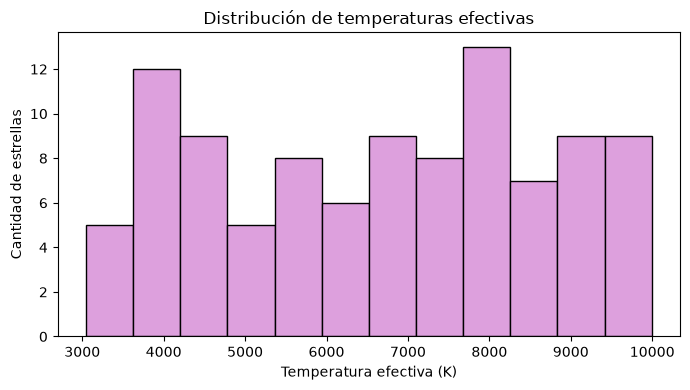

In [75]:
# Grafico la distribución de temperaturas efectivas mediante un histograma.
plt.figure(figsize=(7, 4))
plt.hist(catalogo["Temperatura (K)"], bins=12, color="#DDA0DD", edgecolor="black")
plt.title("Distribución de temperaturas efectivas")
plt.xlabel("Temperatura efectiva (K)")
plt.ylabel("Cantidad de estrellas")
plt.tight_layout()
plt.savefig("hist_temperatura.png", dpi=180)
plt.show()

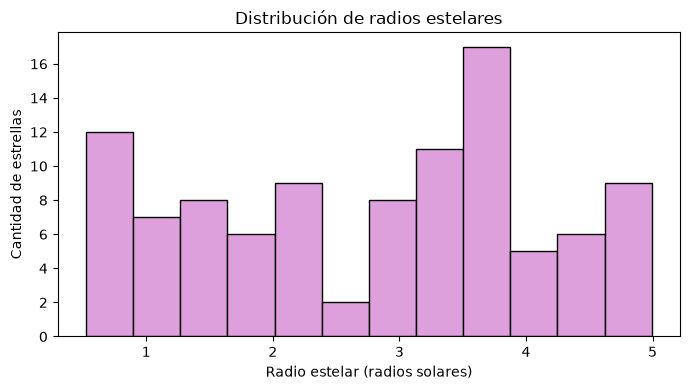

In [76]:
# Grafico la distribución de radios estelares mediante un histograma.
plt.figure(figsize=(7, 4))
plt.hist(catalogo["Radio (Rsol)"], bins=12, color="#DDA0DD", edgecolor="black")
plt.title("Distribución de radios estelares")
plt.xlabel("Radio estelar (radios solares)")
plt.ylabel("Cantidad de estrellas")
plt.tight_layout()
plt.savefig("hist_radio.png", dpi=180)
plt.show()

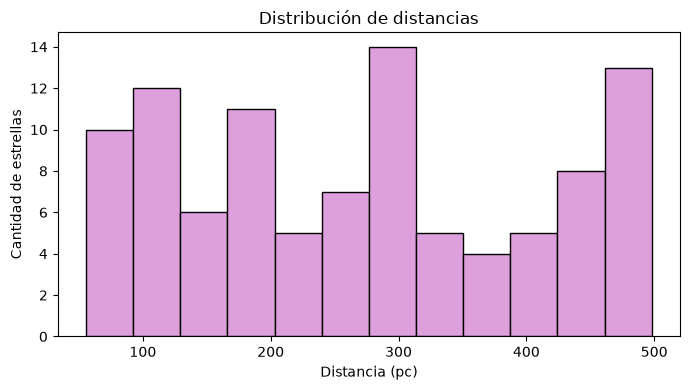

In [77]:
# Grafico la distribución de distancias mediante un histograma.
plt.figure(figsize=(7, 4))
plt.hist(catalogo["Distancia (pc)"], bins=12, color="#DDA0DD", edgecolor="black")
plt.title("Distribución de distancias")
plt.xlabel("Distancia (pc)")
plt.ylabel("Cantidad de estrellas")
plt.tight_layout()
plt.savefig("hist_distancia.png", dpi=180)
plt.show()

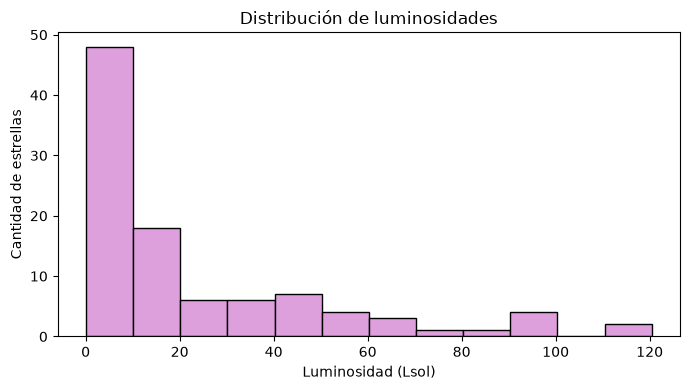

In [78]:
# Grafico la distribución de luminosidades mediante un histograma.
plt.figure(figsize=(7, 4))
plt.hist(catalogo["Luminosidad (Lsol)"], bins=12, color="#DDA0DD", edgecolor="black")
plt.title("Distribución de luminosidades")
plt.xlabel("Luminosidad (Lsol)")
plt.ylabel("Cantidad de estrellas")
plt.tight_layout()
plt.savefig("hist_luminosidad.png", dpi=180)
plt.show()

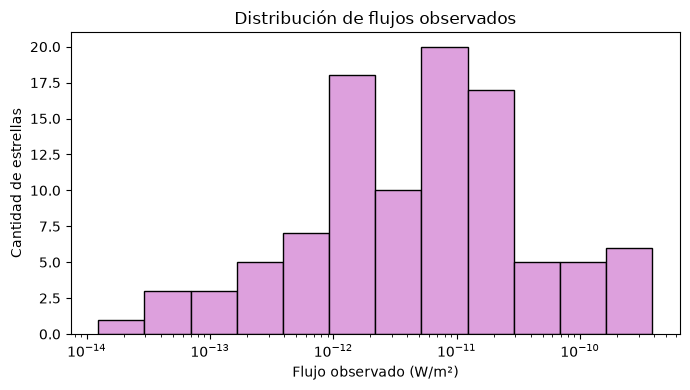

In [79]:
# Grafico la distribución de flujos observados mediante un histograma.
# Se utilizan intervalos en escala logarítmica para representar mejor
# valores que varían en varios órdenes de magnitud.
flujos = catalogo["Flujo (W/m²)"]
bordes = np.logspace(np.log10(flujos.min()), np.log10(flujos.max()), 13)

plt.figure(figsize=(7, 4))
plt.hist(flujos, bins=bordes, color="#DDA0DD", edgecolor="black")
plt.xscale("log")
plt.title("Distribución de flujos observados")
plt.xlabel("Flujo observado (W/m²)")
plt.ylabel("Cantidad de estrellas")
plt.tight_layout()
plt.savefig("hist_flujo.png", dpi=180)
plt.show()

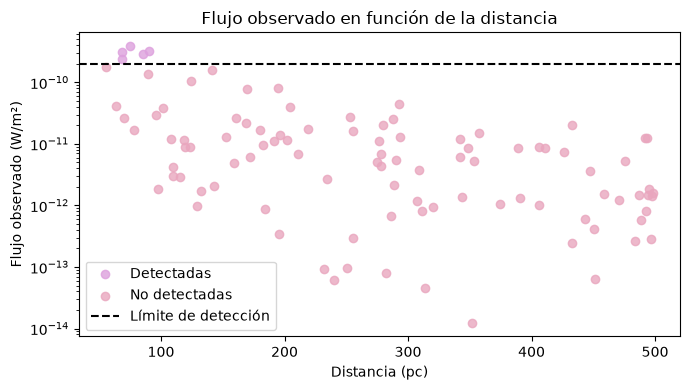

In [80]:
# Separo las estrellas en detectadas y no detectadas usando máscaras.
detectadas = catalogo[catalogo["Clasificacion"] == "Detectada"]
no_detectadas = catalogo[catalogo["Clasificacion"] == "No detectada"]

# Grafico el flujo observado en función de la distancia, distinguiendo las categorías.
plt.figure(figsize=(7, 4))
plt.scatter(detectadas["Distancia (pc)"], detectadas["Flujo (W/m²)"],
            color="#DDA0DD", label="Detectadas", alpha=0.8)
plt.scatter(no_detectadas["Distancia (pc)"], no_detectadas["Flujo (W/m²)"],
            color="#E9A6BE", label="No detectadas", alpha=0.8)
plt.axhline(Flim, color="black", linestyle="--", label="Límite de detección")
plt.yscale("log")
plt.title("Flujo observado en función de la distancia")
plt.xlabel("Distancia (pc)")
plt.ylabel("Flujo observado (W/m²)")
plt.legend()
plt.tight_layout()
plt.savefig("flujo_distancia.png", dpi=180)
plt.show()

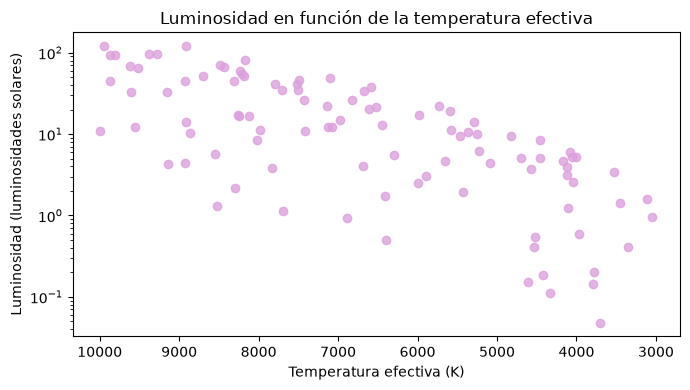

In [81]:
# Represento la luminosidad en función de la temperatura efectiva.
plt.figure(figsize=(7, 4))
plt.scatter(catalogo["Temperatura (K)"], catalogo["Luminosidad (Lsol)"],
            color="#DDA0DD", alpha=0.8)
plt.yscale("log")
plt.gca().invert_xaxis()  # Invierto el eje de temperaturas para ordenarlas de mayor a menor.
plt.title("Luminosidad en función de la temperatura efectiva")
plt.xlabel("Temperatura efectiva (K)")
plt.ylabel("Luminosidad (luminosidades solares)")
plt.tight_layout()
plt.savefig("luminosidad_temperatura.png", dpi=180)
plt.show()